In [94]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk
import string
import numpy as np
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score,accuracy_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans


In [38]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/marcofura/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/marcofura/nltk_data...


True

In [44]:
# Load CSV dataset
PATH_DATASET = "../dataset/test.csv"
df_dataset = pd.read_csv(PATH_DATASET,sep=",",encoding="ISO-8859-1")


In [3]:
df_dataset.columns

Index(['textID', 'text', 'selected_text', 'sentiment', 'Time of Tweet',
       'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)',
       'Density (P/Km²)'],
      dtype='object')

In [45]:
def modificar_dataset(df_dataset):
    df_dataset = df_dataset.rename(columns={"Time of Tweet": "time_of_tweet", "Age of User": "age_user", "Population -2020": "population_2020", "Land Area (Km²)": "land_area_km", "Density (P/Km²)": "density_p_km"})
    df_dataset["sentiment"] = df_dataset["sentiment"].astype("category")
    df_dataset["time_of_tweet"] = df_dataset["time_of_tweet"].astype("category")
    df_dataset["age_user"] = df_dataset["age_user"].astype("category")
    df_dataset["Country"] = df_dataset["Country"].astype("category")
    df_dataset_format = df_dataset[["sentiment", "text", "age_user", "population_2020", "land_area_km", "density_p_km", "time_of_tweet", "Country"]]
    return df_dataset_format

In [46]:
df_dataset.head()

,textID,text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,f87dea47db,Last session of the day http://twitpic.com/67ezh,neutral,morning,0-20,Afghanistan,38928346.0,652860.0,60.0
1,96d74cb729,Shanghai is also really exciting (precisely -...,positive,noon,21-30,Albania,2877797.0,27400.0,105.0
2,eee518ae67,"Recession hit Veronique Branquinho, she has to...",negative,night,31-45,Algeria,43851044.0,2381740.0,18.0
3,01082688c6,happy bday!,positive,morning,46-60,Andorra,77265.0,470.0,164.0
4,33987a8ee5,http://twitpic.com/4w75p - I like it!!,positive,noon,60-70,Angola,32866272.0,1246700.0,26.0


In [47]:
df_dataset_format = modificar_dataset(df_dataset)

In [7]:
df_dataset_format.head()

,sentiment,text,age_user,population_2020,land_area_km,density_p_km,time_of_tweet,Country
0,neutral,"I`d have responded, if I were going",0-20,38928346,652860.0,60,morning,Afghanistan
1,negative,Sooo SAD I will miss you here in San Diego!!!,21-30,2877797,27400.0,105,noon,Albania
2,negative,my boss is bullying me...,31-45,43851044,2381740.0,18,night,Algeria
3,negative,what interview! leave me alone,46-60,77265,470.0,164,morning,Andorra
4,negative,"Sons of ****, why couldn`t they put them on t...",60-70,32866272,1246700.0,26,noon,Angola


In [8]:
df_dataset_format.describe(include="all")

,sentiment,text,age_user,population_2020,land_area_km,density_p_km,time_of_tweet,Country
count,27481,27480,27481,2.748100e+04,2.748100e+04,27481.000000,27481,27481
unique,3,27480,6,NaN,NaN,NaN,3,195
top,neutral,"I`d have responded, if I were going",0-20,NaN,NaN,NaN,morning,Afghanistan
freq,11118,1,4581,NaN,NaN,NaN,9161,149
mean,NaN,NaN,NaN,4.018497e+07,6.621730e+05,357.686583,NaN,NaN
std,NaN,NaN,NaN,1.504946e+08,1.807425e+06,2013.750702,NaN,NaN
min,NaN,NaN,NaN,8.010000e+02,0.000000e+00,2.000000,NaN,NaN
25%,NaN,NaN,NaN,1.968001e+06,2.281000e+04,35.000000,NaN,NaN
50%,NaN,NaN,NaN,8.655535e+06,1.118900e+05,89.000000,NaN,NaN
75%,NaN,NaN,NaN,2.843594e+07,5.279700e+05,214.000000,NaN,NaN


Limpieza de textos

In [9]:
df_dataset_format["text"]

0                      I`d have responded, if I were going
1            Sooo SAD I will miss you here in San Diego!!!
2                                my boss is bullying me...
3                           what interview! leave me alone
4         Sons of ****, why couldn`t they put them on t...
                               ...                        
27476     wish we could come see u on Denver  husband l...
27477     I`ve wondered about rake to.  The client has ...
27478     Yay good for both of you. Enjoy the break - y...
27479                           But it was worth it  ****.
27480       All this flirting going on - The ATG smiles...
Name: text, Length: 27481, dtype: object

Encontrar filas contextos Null o Nan

In [62]:
filas_con_nan = df_dataset_format[df_dataset_format.isna().any(axis=1)]

In [63]:
filas_con_nan

,sentiment,text,age_user,population_2020,land_area_km,density_p_km,time_of_tweet,Country,text_clean,sentiment_codes


In [61]:
df_dataset_format["text"].fillna("", inplace=True)

/var/folders/xw/ksr09pc96kqcwxk95_zhnv080000gn/T/ipykernel_55562/595160342.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_dataset_format["text"].fillna("", inplace=True)


In [60]:
df_dataset_format.dropna(inplace=True)

In [64]:
def clean_text(text):
    # Convertir el texto a minúsculas
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    text = text.translate(str.maketrans('', '', string.punctuation))
    # Eliminar caracteres especiales y números
    text = re.sub(r"[^a-z\s]", "", text)
    

    # Eliminar stopwords
    stop_words = set(stopwords.words("english"))
    text = " ".join([word for word in text.split() if word not in stop_words])
    # Lematización
    lemmatizer = WordNetLemmatizer()
    text = " ".join([lemmatizer.lemmatize(word) for word in text.split()])
    return text

In [65]:
df_dataset_format["text_clean"] = df_dataset_format["text"].apply(clean_text)

In [66]:
df_dataset_format["sentiment_codes"] = pd.Categorical(df_dataset_format["sentiment"]).codes

In [67]:
df_dataset_format["sentiment_codes"].unique()

array([1, 2, 0], dtype=int8)

In [68]:
df_dataset_format["text_clean"][:20]

0                                      last session day
1     shanghai also really exciting precisely skyscr...
2     recession hit veronique branquinho quit compan...
3                                            happy bday
4                                                  like
5                              thats great weee visitor
6                               think everyone hate lol
7     soooooo wish could im school myspace completel...
8                           within short time last clue
9     get day alright havent done anything yet leavi...
10          bike put holdshould known argh total bummer
11                                    checked didnt win
12                       youre twitter tavern bore much
13    im va weekend youngest son turn tomorrowit mak...
14    coming socket feel like phone hole virgin that...
15      hot today dont like hate new timetable bad week
16                                                 miss
17                                              

In [18]:
def vectorizar_texto(texto):
    vectorizer = CountVectorizer(stop_words="english",min_df=5)
    X = vectorizer.fit_transform(texto)
    df_bow = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
    return df_bow,vectorizer

In [69]:
def vectorizar_tfidf(texto):
    vectorizer = TfidfVectorizer(stop_words="english",min_df=5)
    X = vectorizer.fit_transform(texto)
    df_bow = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
    return df_bow,vectorizer

In [20]:
df_bow,vectorizer = vectorizar_texto(df_dataset_format["text_clean"])

In [21]:
vocabulario = vectorizer.vocabulary_

In [22]:
vocabulario

{'id': 1645,
 'going': 1363,
 'sooo': 3058,
 'sad': 2813,
 'miss': 2132,
 'san': 2825,
 'diego': 894,
 'bos': 370,
 'interview': 1704,
 'leave': 1890,
 'son': 3052,
 'release': 2714,
 'bought': 376,
 'best': 294,
 'ranger': 2654,
 'forum': 1262,
 'earth': 1012,
 'feeding': 1175,
 'baby': 214,
 'fun': 1297,
 'smile': 3014,
 'soooo': 3059,
 'high': 1547,
 'journey': 1773,
 'wow': 3729,
 'cooler': 711,
 'hehe': 1527,
 'possible': 2533,
 'love': 1989,
 'hopeful': 1599,
 'reckon': 2684,
 'chance': 530,
 'im': 1659,
 'gonna': 1370,
 'cake': 468,
 'stuff': 3178,
 'really': 2675,
 'like': 1920,
 'song': 3053,
 'story': 3156,
 'taylor': 3276,
 'swift': 3238,
 'running': 2807,
 'low': 1997,
 'want': 3606,
 'music': 2204,
 'tonight': 3393,
 'lost': 1983,
 'voice': 3583,
 'test': 3302,
 'uh': 3508,
 'oh': 2316,
 'sunburned': 3203,
 'trying': 3449,
 'plot': 2503,
 'speak': 3084,
 'sigh': 2953,
 'ive': 1726,
 'sick': 2950,
 'past': 2411,
 'day': 828,
 'hair': 1462,
 'look': 1971,
 'didnt': 891,
 'ha

In [23]:
df_bow.head(10)

,aaaah,aah,abandoned,ability,abit,able,absolutely,abt,ac,academy,...,yu,yucky,yum,yummy,yup,zealand,zero,zombie,zone,zoo
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [70]:
df_tfidf, vectorizer_tfidf = vectorizar_tfidf(df_dataset_format["text_clean"])

In [71]:
df_tfidf.shape

(3534, 796)

In [72]:
df_tfidf.describe()

,able,absolutely,access,account,actually,added,ago,agree,ah,ahh,...,year,yep,yes,yesterday,yo,youll,youre,youtube,yr,yup
count,3534.000000,3534.000000,3534.00000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,...,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000,3534.000000
mean,0.001032,0.001399,0.00088,0.001365,0.002991,0.000839,0.001078,0.001739,0.000863,0.000808,...,0.004178,0.001376,0.006882,0.002815,0.000814,0.000869,0.006556,0.001157,0.000841,0.001661
std,0.022114,0.028151,0.02193,0.027843,0.037057,0.020631,0.023121,0.034186,0.021514,0.021676,...,0.042762,0.029226,0.066578,0.038695,0.020556,0.021296,0.061379,0.024429,0.023829,0.033682
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,0.610732,0.728278,0.74864,0.855337,0.646908,0.656211,0.618302,1.000000,0.692748,0.697869,...,0.861358,0.712469,1.000000,0.803683,0.719511,0.637040,1.000000,0.600343,1.000000,1.000000


In [27]:
pca_pipe = make_pipeline(StandardScaler(), PCA())
pca_pipe.fit(df_tfidf)

# Se extrae el modelo entrenado del pipeline
modelo_pca = pca_pipe.named_steps["pca"]


In [28]:
# Se combierte el array a dataframe para añadir nombres a los ejes.
df_pca_components = pd.DataFrame(
    data=modelo_pca.components_,
    columns=df_tfidf.columns,
    index=["PC{}".format(i+1) for i in range(modelo_pca.n_components_)],
)


In [29]:
df_pca_components

,aaaah,aah,abandoned,ability,abit,able,absolutely,abt,ac,academy,...,yu,yucky,yum,yummy,yup,zealand,zero,zombie,zone,zoo
PC1,-0.003182,0.001115,-0.003222,-0.002589,-0.005263,-0.015381,-0.001996,-0.007864,-0.009768,-0.000961,...,0.000284,-0.000800,-0.002736,0.004401,0.002205,0.008878,-0.000603,0.000193,-0.001717,0.002466
PC2,-0.003104,0.001595,-0.005159,0.003678,0.000223,0.011810,-0.001388,0.001455,-0.001676,0.012754,...,-0.002819,0.003147,-0.045290,-0.050917,0.008436,0.023304,0.006274,0.015863,-0.000311,-0.002936
PC3,-0.001190,-0.003968,0.006323,-0.005181,0.000936,-0.032107,0.020881,-0.012619,0.002588,0.009606,...,0.002317,0.006453,0.058027,0.054907,0.008855,0.010496,-0.007161,0.006955,0.003519,-0.000246
PC4,-0.004008,0.001716,-0.004030,-0.001073,-0.001462,0.001525,0.019815,0.008158,-0.009392,-0.006633,...,-0.001512,-0.007388,-0.007349,-0.013599,-0.006166,-0.000333,0.005474,0.000668,0.003363,0.003399
PC5,-0.003097,-0.005091,-0.008674,0.006644,-0.004524,0.005666,0.005396,-0.000042,0.003403,0.003907,...,-0.006514,-0.004069,0.063819,0.059372,-0.000817,-0.007186,0.007803,-0.049321,0.002647,-0.004469
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
PC3795,0.001421,0.001051,0.000389,-0.000273,-0.000931,0.000023,0.001099,-0.000772,0.000056,-0.002595,...,-0.000626,0.000701,0.001549,0.002393,0.000700,-0.001398,0.002031,0.051049,0.000548,-0.000326
PC3796,-0.000473,0.000462,-0.000129,-0.000088,0.019671,-0.000077,0.000510,0.000717,0.000511,0.001219,...,-0.000991,0.000159,0.000503,0.000216,0.005110,0.001109,0.000062,0.000166,-0.000186,-0.001151
PC3797,0.001052,-0.000710,-0.000264,0.002168,0.000236,-0.001690,0.009402,0.000839,0.000009,0.000790,...,-0.000129,0.002285,0.003872,0.021141,0.000303,0.000544,-0.000865,0.002170,0.000959,0.001658
PC3798,-0.000194,-0.000125,-0.002354,0.000726,-0.000355,0.002025,0.000176,-0.000412,0.000512,-0.000153,...,0.000062,0.000242,-0.000969,0.017454,-0.000422,-0.000561,0.000206,-0.000751,-0.000452,-0.000044


In [30]:
print("Porcentaje de varianza explicada por cada componente")
print(modelo_pca.explained_variance_ratio_)
# Calculate cumulative explained variance ratio
cumulative_variance_ratio = np.cumsum(modelo_pca.explained_variance_ratio_)

# Print cumulative explained variance ratio
print("Porcentaje de varianza acumulada por cada componente")
print(cumulative_variance_ratio)

Porcentaje de varianza explicada por cada componente
[6.81662805e-04 5.71440309e-04 5.60679886e-04 ... 5.39828091e-05
 4.19510751e-05 3.21207755e-05]
Porcentaje de varianza acumulada por cada componente
[6.81662805e-04 1.25310311e-03 1.81378300e-03 ... 9.99925928e-01
 9.99967879e-01 1.00000000e+00]


In [31]:
cumulative_variance_ratio[2829]

0.8500189965241794

In [32]:
np.where(cumulative_variance_ratio>0.85)

(array([2829, 2830, 2831, 2832, 2833, 2834, 2835, 2836, 2837, 2838, 2839,
        2840, 2841, 2842, 2843, 2844, 2845, 2846, 2847, 2848, 2849, 2850,
        2851, 2852, 2853, 2854, 2855, 2856, 2857, 2858, 2859, 2860, 2861,
        2862, 2863, 2864, 2865, 2866, 2867, 2868, 2869, 2870, 2871, 2872,
        2873, 2874, 2875, 2876, 2877, 2878, 2879, 2880, 2881, 2882, 2883,
        2884, 2885, 2886, 2887, 2888, 2889, 2890, 2891, 2892, 2893, 2894,
        2895, 2896, 2897, 2898, 2899, 2900, 2901, 2902, 2903, 2904, 2905,
        2906, 2907, 2908, 2909, 2910, 2911, 2912, 2913, 2914, 2915, 2916,
        2917, 2918, 2919, 2920, 2921, 2922, 2923, 2924, 2925, 2926, 2927,
        2928, 2929, 2930, 2931, 2932, 2933, 2934, 2935, 2936, 2937, 2938,
        2939, 2940, 2941, 2942, 2943, 2944, 2945, 2946, 2947, 2948, 2949,
        2950, 2951, 2952, 2953, 2954, 2955, 2956, 2957, 2958, 2959, 2960,
        2961, 2962, 2963, 2964, 2965, 2966, 2967, 2968, 2969, 2970, 2971,
        2972, 2973, 2974, 2975, 2976, 

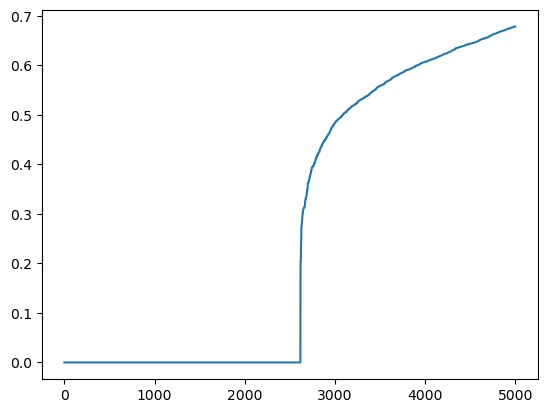

In [33]:
# Asumiendo df_usa_arrests_scaled como tus datos escalados
neighbors = NearestNeighbors(n_neighbors=2)
neighbors_fit = neighbors.fit(df_tfidf)
distances, indices = neighbors_fit.kneighbors(df_tfidf)

# Ordenar y plotear las distancias
distances = np.sort(distances, axis=0)
distances = distances[:, 1]
plt.plot(distances[:5000])
plt.show()

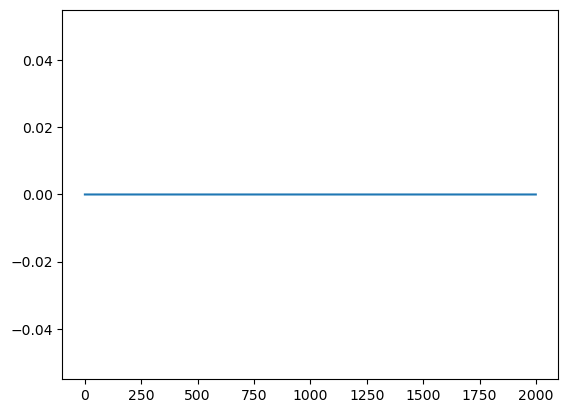

In [102]:
plt.plot(distances[:2000])
plt.show()

In [95]:
distances.shape

(27481,)

In [43]:
df_tfidf[1:5]

,aaaah,aah,abandoned,ability,abit,able,absolutely,abt,ac,academy,...,yu,yucky,yum,yummy,yup,zealand,zero,zombie,zone,zoo
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [73]:
# Suponiendo que 'X' son tus datos de 4000 columnas
X_embedded = TSNE(n_components=2, perplexity=30,verbose=1).fit_transform(df_tfidf)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3534 samples in 0.001s...
[t-SNE] Computed neighbors for 3534 samples in 0.127s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3534
[t-SNE] Computed conditional probabilities for sample 2000 / 3534
[t-SNE] Computed conditional probabilities for sample 3000 / 3534
[t-SNE] Computed conditional probabilities for sample 3534 / 3534
[t-SNE] Mean sigma: 0.000000
[t-SNE] KL divergence after 250 iterations with early exaggeration: 77.573029
[t-SNE] KL divergence after 1000 iterations: 1.932875


In [74]:
X_embedded[1:4]

array([[-5.3677435, 17.502882 ],
       [20.347609 , 14.886788 ],
       [23.119247 , 38.436676 ]], dtype=float32)

Primera Evaluación

In [75]:
dbscan_1 = DBSCAN(eps=0.1, min_samples=2).fit(df_tfidf)
y_dbs1 = dbscan_1.labels_

In [76]:
def mostrar_cantidad_grupos(labels):
    unique, counts = np.unique(labels, return_counts=True)
    iterator = dict(zip(unique, counts))
    for el in iterator:
        print("Grupo ",(el+1) if el!=-1 else "Ruido",": ",iterator[el]," Porcentage: ",(iterator[el]/len(labels)*100).round(2),"%")

In [77]:
def graficar_clasificacion(X_embedded, y_dbs1):
    # Visualización
    plt.figure(figsize=(10, 6))
    plt.scatter(
        X_embedded[:, 0], X_embedded[:, 1], c=y_dbs1, cmap="viridis"
    )  # 'y_dbs1' son tus etiquetas de cluster
    plt.colorbar()
    plt.title("Visualización de DBSCAN con t-SNE")
    plt.xlabel("Componente 1")
    plt.ylabel("Componente 2")
    plt.show()

In [78]:
def mostrar_metricas(y_dbs1):
    indices_no_ruido_1 = y_dbs1 != -1

    score = silhouette_score(df_tfidf[indices_no_ruido_1], y_dbs1[indices_no_ruido_1])
    print("Silhouette Score Clasificación sin considerar el ruido: ", score)

In [79]:
mostrar_cantidad_grupos(y_dbs1)

Grupo  Ruido :  3102  Porcentage:  87.78 %
Grupo  1 :  6  Porcentage:  0.17 %
Grupo  2 :  5  Porcentage:  0.14 %
Grupo  3 :  2  Porcentage:  0.06 %
Grupo  4 :  3  Porcentage:  0.08 %
Grupo  5 :  8  Porcentage:  0.23 %
Grupo  6 :  138  Porcentage:  3.9 %
Grupo  7 :  3  Porcentage:  0.08 %
Grupo  8 :  2  Porcentage:  0.06 %
Grupo  9 :  10  Porcentage:  0.28 %
Grupo  10 :  2  Porcentage:  0.06 %
Grupo  11 :  4  Porcentage:  0.11 %
Grupo  12 :  4  Porcentage:  0.11 %
Grupo  13 :  7  Porcentage:  0.2 %
Grupo  14 :  10  Porcentage:  0.28 %
Grupo  15 :  2  Porcentage:  0.06 %
Grupo  16 :  5  Porcentage:  0.14 %
Grupo  17 :  5  Porcentage:  0.14 %
Grupo  18 :  5  Porcentage:  0.14 %
Grupo  19 :  3  Porcentage:  0.08 %
Grupo  20 :  2  Porcentage:  0.06 %
Grupo  21 :  3  Porcentage:  0.08 %
Grupo  22 :  2  Porcentage:  0.06 %
Grupo  23 :  6  Porcentage:  0.17 %
Grupo  24 :  3  Porcentage:  0.08 %
Grupo  25 :  5  Porcentage:  0.14 %
Grupo  26 :  2  Porcentage:  0.06 %
Grupo  27 :  3  Porcentage: 

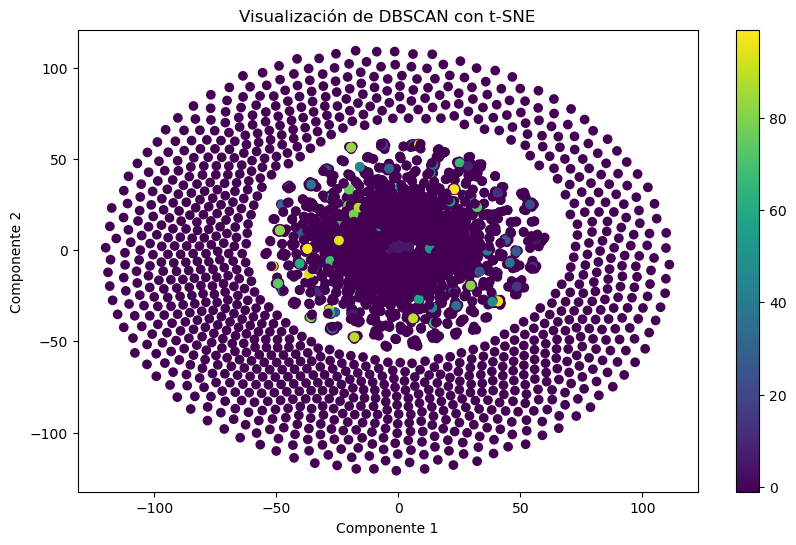

In [80]:
graficar_clasificacion(X_embedded, y_dbs1)

In [81]:
mostrar_metricas(y_dbs1)

Silhouette Score Clasificación sin considerar el ruido:  0.9999999997398106


Segunda Evaluación

In [82]:
dbscan_2 = DBSCAN(eps=0.995, min_samples=45).fit(df_tfidf)
y_dbs2 = dbscan_2.labels_

In [83]:
mostrar_cantidad_grupos(y_dbs2)

Grupo  Ruido :  3334  Porcentage:  94.34 %
Grupo  1 :  138  Porcentage:  3.9 %
Grupo  2 :  62  Porcentage:  1.75 %


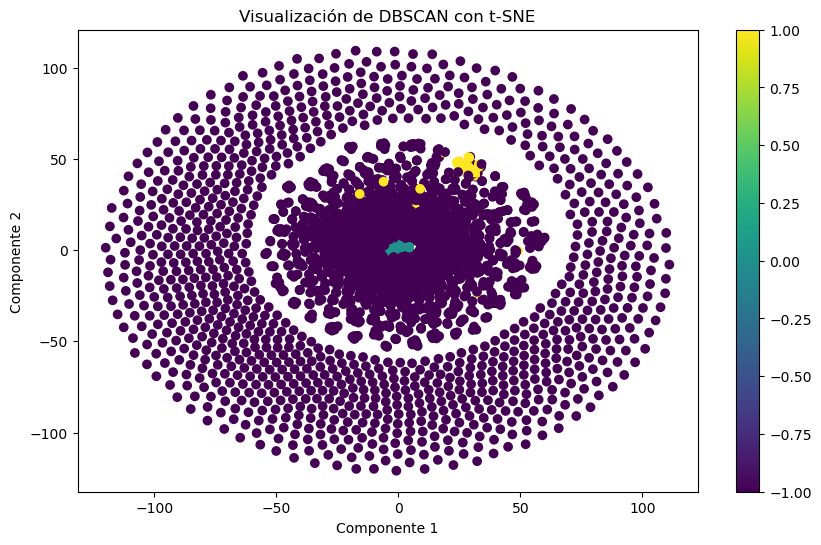

In [84]:
graficar_clasificacion(X_embedded, y_dbs2)

In [85]:
mostrar_metricas(y_dbs2)

Silhouette Score Clasificación sin considerar el ruido:  0.6938669924753345


Tercera Evaluación

In [86]:
dbscan_3 = DBSCAN(eps=0.01, min_samples=500).fit(df_tfidf)
y_dbs3 = dbscan_3.labels_

In [87]:
mostrar_cantidad_grupos(y_dbs3)

Grupo  Ruido :  3534  Porcentage:  100.0 %


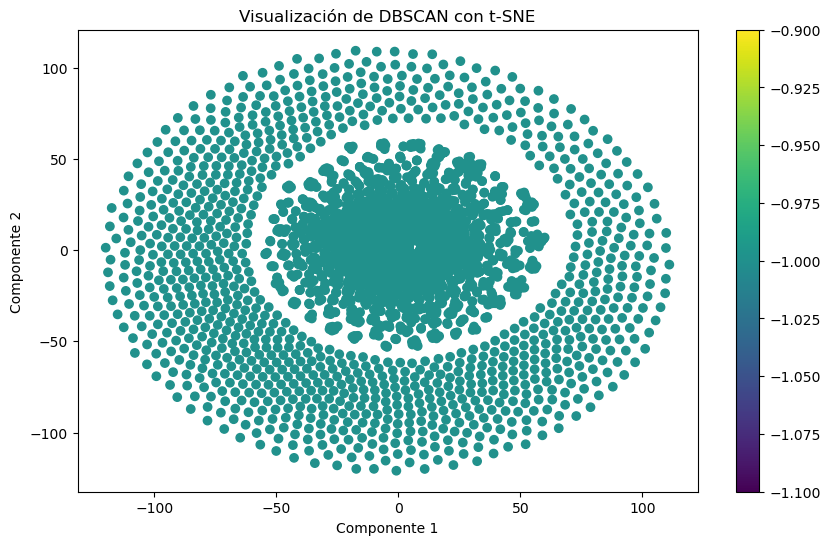

In [88]:
graficar_clasificacion(X_embedded, y_dbs3)

In [89]:
mostrar_metricas(y_dbs3)

ValueError: Found array with 0 sample(s) (shape=(0, 796)) while a minimum of 1 is required.

Mixturas Gaussianas

In [120]:
gm_1 = GaussianMixture(n_components=3, random_state=0, covariance_type="full").fit(
    df_tfidf
)
print(gm_1.means_)

print(gm_1.covariances_)

y_gmm1 = gm_1.predict(df_tfidf)

[[0.0010028  0.0010254  0.00112006 ... 0.0012881  0.00092584 0.00167997]
 [0.0010415  0.00224757 0.         ... 0.         0.00091824 0.00124477]
 [0.00127016 0.0034826  0.         ... 0.00160022 0.         0.00206363]]
[[[ 4.89412125e-04 -1.02827455e-06 -1.12319711e-06 ... -1.29170770e-06
   -9.28437507e-07 -1.68467656e-06]
  [-1.02827455e-06  6.06948444e-04 -1.14850983e-06 ... -1.32081803e-06
   -9.49361062e-07 -1.72264295e-06]
  [-1.12319711e-06 -1.14850983e-06  6.12587201e-04 ... -1.44274600e-06
   -1.03699892e-06  9.86834811e-05]
  ...
  [-1.29170770e-06 -1.32081803e-06 -1.44274600e-06 ...  6.65845675e-04
   -1.19257740e-06 -2.16396599e-06]
  [-9.28437507e-07 -9.49361062e-07 -1.03699892e-06 ... -1.19257740e-06
    6.65483188e-04 -1.55538841e-06]
  [-1.68467656e-06 -1.72264295e-06  9.86834811e-05 ... -2.16396599e-06
   -1.55538841e-06  1.18145502e-03]]

 [[ 4.73939234e-04 -2.34084698e-06  0.00000000e+00 ...  0.00000000e+00
   -9.56351466e-07 -1.29642438e-06]
  [-2.34084698e-06  1.1

In [121]:
mostrar_cantidad_grupos(y_gmm1)

Grupo  1 :  2777  Porcentage:  78.58 %
Grupo  2 :  437  Porcentage:  12.37 %
Grupo  3 :  320  Porcentage:  9.05 %


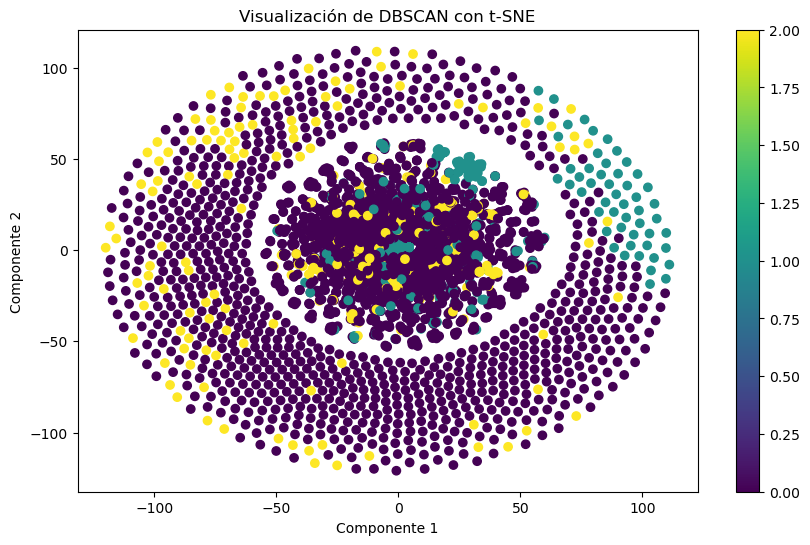

In [122]:
graficar_clasificacion(X_embedded, y_gmm1)

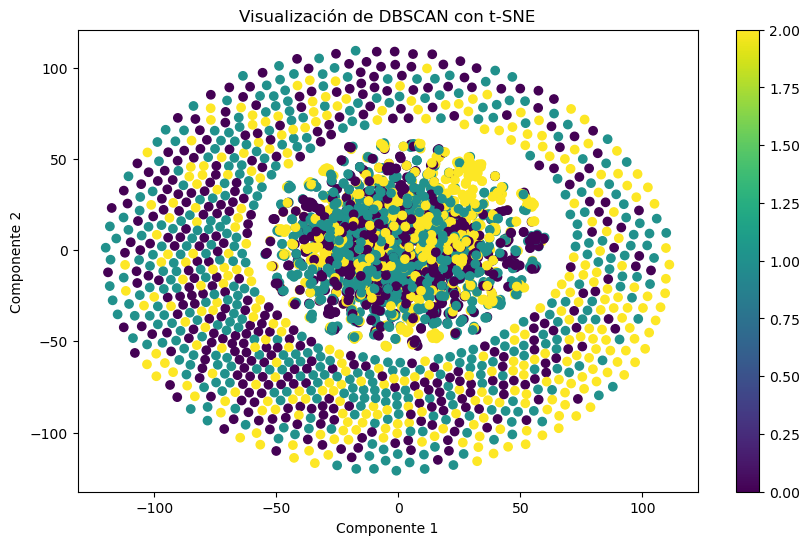

In [123]:
graficar_clasificacion(X_embedded, df_dataset_format["sentiment_codes"])

In [288]:
def mostrar_lista_accuracy(labels):
    mapeo_1 = {0:0,1:2,2:1}
    mapeo_2 = {0:1,1:0,2:2}
    mapeo_3 = {0:1,1:2,2:0}
    mapeo_4 = {0:2,1:1,2:0}
    mapeo_5 = {0:2,1:0,2:1}
    y_gmm1_mapped = np.vectorize(mapeo_1.get)(labels)
    y_gmm2_mapped = np.vectorize(mapeo_2.get)(labels)
    y_gmm3_mapped = np.vectorize(mapeo_3.get)(labels)
    y_gmm4_mapped = np.vectorize(mapeo_4.get)(labels)
    y_gmm5_mapped = np.vectorize(mapeo_5.get)(labels)
    precision = accuracy_score(df_dataset_format["sentiment_codes"], y_gmm1_mapped)

    print(f"La precisión del modelo es: {precision}")
    precision = accuracy_score(df_dataset_format["sentiment_codes"], y_gmm2_mapped)
    
    print(f"La precisión del modelo es: {precision}")
    precision = accuracy_score(df_dataset_format["sentiment_codes"], y_gmm3_mapped)
    
    print(f"La precisión del modelo es: {precision}")
    precision = accuracy_score(df_dataset_format["sentiment_codes"], y_gmm4_mapped)
    
    print(f"La precisión del modelo es: {precision}")
    precision = accuracy_score(df_dataset_format["sentiment_codes"], y_gmm5_mapped)
    
    print(f"La precisión del modelo es: {precision}")

In [305]:
mostrar_lista_accuracy(y_gmm1)

La precisión del modelo es: 0.3204759652123285
La precisión del modelo es: 0.37116553254976165
La precisión del modelo es: 0.29220188493868493
La precisión del modelo es: 0.30835850223790984
La precisión del modelo es: 0.342927841053819


In [263]:
mostrar_metricas(y_gmm1)

Silhouette Score Clasificación sin considerar el ruido:  0.00928421204849256


In [95]:
scaler = StandardScaler()
datos_escalado = scaler.fit_transform(df_tfidf)
datos_escalado

array([[-0.04666517, -0.04970507, -0.0401394 , ..., -0.04737217,
        -0.03530053, -0.04931753],
       [-0.04666517, -0.04970507, -0.0401394 , ..., -0.04737217,
        -0.03530053, -0.04931753],
       [-0.04666517, -0.04970507, -0.0401394 , ..., -0.04737217,
        -0.03530053, -0.04931753],
       ...,
       [-0.04666517, -0.04970507, -0.0401394 , ..., -0.04737217,
        -0.03530053, -0.04931753],
       [-0.04666517, -0.04970507, -0.0401394 , ..., 17.89295122,
        -0.03530053, -0.04931753],
       [-0.04666517, -0.04970507, -0.0401394 , ..., -0.04737217,
        -0.03530053, -0.04931753]])

In [112]:
def calcular_wcss(data):
    wcss = []
    for k in range(400, 600):
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(data)
        wcss.append(kmeans.inertia_)
    return wcss

wcss = calcular_wcss(datos_escalado)


plt.figure(figsize=(8, 4))
plt.plot(range(400, 600), wcss, marker='o', linestyle='--')
plt.xlabel('clusters')
plt.ylabel('WCSS')
plt.xticks(range(400, 600))
plt.grid(True)
plt.show()

KeyboardInterrupt: 

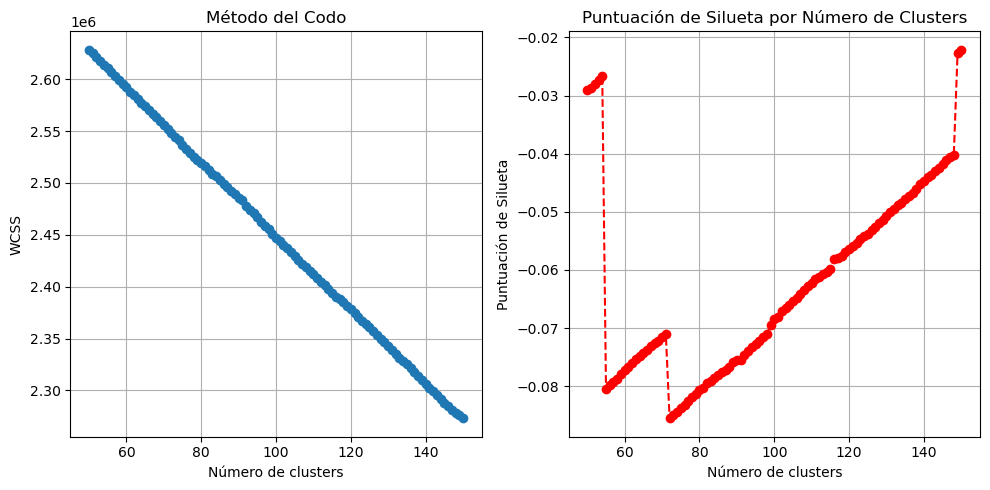

In [117]:
from sklearn.metrics import silhouette_score

def calcular_wcss_y_silueta(data, k_min=2, k_max=10):
    wcss = []
    siluetas = []
    for k in range(k_min, k_max + 1):
        kmeans = KMeans(n_clusters=k, random_state=42)
        kmeans.fit(data)
        wcss.append(kmeans.inertia_)
        silueta = silhouette_score(data, kmeans.labels_)
        siluetas.append(silueta)
    return wcss, siluetas

# Ajusta los valores de k_min y k_max según sea necesario
wcss, siluetas = calcular_wcss_y_silueta(datos_escalado, 50, 150)

# Graficar WCSS
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(range(50, 151), wcss, marker='o', linestyle='--')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.title('Método del Codo')
plt.grid(True)

# Graficar Silueta
plt.subplot(1, 2, 2)
plt.plot(range(50, 151), siluetas, marker='o', linestyle='--', color='red')
plt.xlabel('Número de clusters')
plt.ylabel('Puntuación de Silueta')
plt.title('Puntuación de Silueta por Número de Clusters')
plt.grid(True)

plt.tight_layout()
plt.show()

In [103]:
datos_escalado.shape

(3534, 796)

In [97]:

kmeans = KMeans(n_clusters=3, random_state=42)

kmeans.fit(datos_escalado)

df_dataset_format['kmeans_labels'] = kmeans.predict(datos_escalado)
df_dataset_format.head()

,sentiment,text,age_user,population_2020,land_area_km,density_p_km,time_of_tweet,Country,text_clean,sentiment_codes,kmeans_labels
0,neutral,Last session of the day http://twitpic.com/67ezh,0-20,38928346.0,652860.0,60.0,morning,Afghanistan,last session day,1,2
1,positive,Shanghai is also really exciting (precisely -...,21-30,2877797.0,27400.0,105.0,noon,Albania,shanghai also really exciting precisely skyscr...,2,2
2,negative,"Recession hit Veronique Branquinho, she has to...",31-45,43851044.0,2381740.0,18.0,night,Algeria,recession hit veronique branquinho quit compan...,0,2
3,positive,happy bday!,46-60,77265.0,470.0,164.0,morning,Andorra,happy bday,2,2
4,positive,http://twitpic.com/4w75p - I like it!!,60-70,32866272.0,1246700.0,26.0,noon,Angola,like,2,2


In [118]:
ss= silhouette_score(datos_escalado, df_dataset_format['kmeans_labels'])
print(f'Silhouette Score: {ss}')

Silhouette Score: 0.06110821183859044


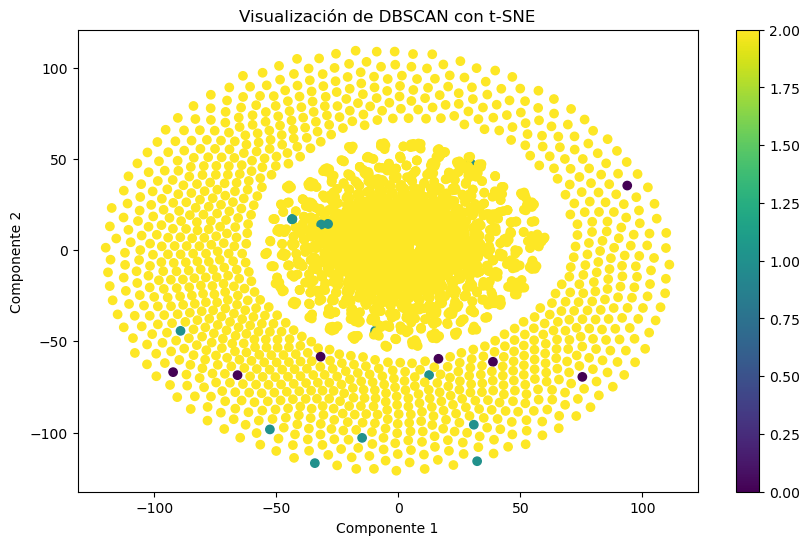

In [119]:
graficar_clasificacion(X_embedded, df_dataset_format['kmeans_labels'])